# Hypothesis Generation

**Demo 3:** (Breadth → Synthesis → **Discovery**)

### Overview
A powerful capability of the System Public Graph is that you can use its data to point at what *hasn't yet been studied*. If two concepts each share strong evidence with the same set of intermediate concepts but have never been studied directly against each other, that gap is a testable hypothesis. This is a classic literature-based discovery pattern: [Don Swanson used it in the 1980s](https://doi.org/10.1353/pbm.1986.0087) to predict a link between fish oil and Raynaud's syndrome from two literatures that never cited each other, with the hypothesis later confirmed by a clinical trial.

Here, you'll run that same pattern on the **diabetic retinopathy** landscape explored in the previous demo, to find a hypothesis candidate for further investigation.

## 0. Setup & Auth

As noted in Demos 1 and 2, everything below runs on one API key and one auth header, reused for every call in this notebook. Simply replace `YOUR_API_KEY` with your Beta API key and you're set up for the rest of the walkthrough.

You're also defining four small helpers here that you'll see reused throughout: `get_json` for a single request, `paginate_all` for walking through multi-page results, `find_exact_concept` for handling a quirk in how concept search ranks results (more on that in Section 1), and `relationship_exists` for checking whether two concepts already have a direct relationship in the graph.

In [ ]:
import time
from collections import Counter, defaultdict

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import requests

API_KEY = "YOUR_API_KEY"  # replace with your beta API key
BASE_URL = "https://public-api.system.com"
HEADERS = {"x-api-key": API_KEY}


def get_json(path, params=None):
    """GET a Public Graph endpoint and return the parsed JSON body."""
    resp = requests.get(f"{BASE_URL}{path}", headers=HEADERS, params=params or {})
    resp.raise_for_status()
    return resp.json()


def paginate_all(path, params=None, page_size=100, max_records=None, sleep_s=0.0):
    """Walk a paginated list endpoint (offset/limit) and return records, up to max_records if set."""
    params = dict(params or {})
    params["limit"] = page_size
    params["include_total"] = True
    offset = 0
    records = []
    total = None
    while total is None or offset < total:
        params["offset"] = offset
        page = get_json(path, params)
        records.extend(page["data"])
        total = page.get("total", len(records))
        offset += page_size
        if sleep_s:
            time.sleep(sleep_s)
        if not page["data"]:
            break
        if max_records and len(records) >= max_records:
            records = records[:max_records]
            break
    return records, total


def find_exact_concept(label, page_size=50, max_records=500):
    """Search concepts by label and return the one whose wikidata_label matches exactly.

    The canonical concept isn't always the top search hit — subtypes and aliases (e.g.
    'background diabetic retinopathy') can outrank it. We page through search results looking
    for an exact (case-insensitive) label match instead of trusting the first few hits.
    """
    hits, _ = paginate_all(
        "/v1/concepts", {"search": f"wikidata_label:{label}"},
        page_size=page_size, max_records=max_records,
    )
    exact = [c for c in hits if c["wikidata_label"].strip().lower() == label.strip().lower()]
    if not exact:
        seen = "\n".join(f"  {c['system_id']} - {c['wikidata_label']}" for c in hits[:20])
        raise ValueError(
            f"No concept with the exact label '{label}' turned up in the first {len(hits)} "
            f"search hits.\nClosest matches seen:\n{seen}\n"
            "Try raising max_records, or pick the right system_id manually from the list above."
        )
    return exact[0]


def relationship_exists(concept_id_a, concept_id_b):
    """Check whether a direct relationship exists between two concepts, in either direction."""
    for rel_id in (f"{concept_id_a}|{concept_id_b}", f"{concept_id_b}|{concept_id_a}"):
        try:
            get_json(f"/v1/relationships/{rel_id.replace('|', '%7C')}")
            return True
        except requests.HTTPError:
            continue
    return False

## 1. Concept lookup

First, ground the topic to its canonical concept to anchor everything that follows.

**Note:** The canonical concept isn't always the top search hit; subtypes like "background diabetic retinopathy" or "severe nonproliferative diabetic retinopathy" can outrank plain "diabetic retinopathy" in the search results. To account for this, use `find_exact_concept()` (defined in Setup) to page through results until it finds an exact label match.

In [2]:
dr_concept = find_exact_concept("diabetic retinopathy")
dr_concept

{'system_id': 'O0vVvNvNdN',
 'wikidata_label': 'diabetic retinopathy',
 'wikidata_id': 'Q631361',
 'wikidata_description': 'human disease',
 'wikidata_aliases': ['diabetic eye disease',
  'retinal abnormality - diabetes-related',
  'diabetes mellitus insulin dependent type, not stated as uncontrolled, with ophthalmic manifestations',
  'diabetes mellitus juvenile type, not stated as uncontrolled, with ophthalmic manifestations',
  'diabetes mellitus type I [insulin dependent type] [IDDM] [juvenile type], not stated as uncontrolled, with ophthalmic manifestations',
  'diabetic oculopathy']}

## 2. First hop

Start by pulling **diabetic retinopathy**'s direct relationships, exactly as you did in Demo 1. The concepts on the other side of those relationships are **diabetic retinopathy**'s *neighbors*, and they do two jobs here: the best-evidenced ones are the set you'll use to explore outward, and the full list becomes your exclusion list, since a "new" hypothesis can't be something the literature already studies directly.

**Note:** Here, *best-evidenced* means the most supporting studies — System sorts by `num_studies` and takes the top `N_NEIGHBORS`. That's evidence *volume*, not effect size and not statistical significance. We use it because a neighbor backed by fifty studies is a more dependable stepping stone than one backed by a single paper, whatever either one reports. Note that this methodology does, however, carry a known bias: well-funded, heavily-studied topics rise to the top, so the paths we explore run through the parts of the literature that already get the most attention.

In [3]:
MAX_RECORDS = 300  # demo-speed cap; raise or remove for a full pull
N_NEIGHBORS = 30   # how many of diabetic retinopathy's best-evidenced neighbors to explore outward from

dr_relationships, true_total = paginate_all(
    f"/v1/concepts/{dr_concept['system_id']}/relationships",
    {"sort": "num_studies:desc"},
    max_records=MAX_RECORDS,
)


def other_concept(rel, anchor_id):
    """Return whichever side of the relationship isn't the anchor."""
    if rel["source_concept"]["system_id"] == anchor_id:
        return rel["target_concept"]
    return rel["source_concept"]


# Drop the self-relationship (the concept related to itself) -- a real record, but not
# a connection to anywhere else, so it has no role in a two-hop traversal.
dr_relationships = [
    r for r in dr_relationships
    if r["source_concept"]["system_id"] != r["target_concept"]["system_id"]
]

# Everything directly connected to diabetic retinopathy -- our exclusion list for later.
direct_neighbors = {}
for rel in dr_relationships:
    other = other_concept(rel, dr_concept["system_id"])
    direct_neighbors[other["system_id"]] = other["wikidata_label"]

# The best-evidenced neighbors are the ones we'll explore outward from.
neighbors_to_explore = []
seen_neighbor_ids = set()
for rel in dr_relationships:
    other = other_concept(rel, dr_concept["system_id"])
    if other["system_id"] not in seen_neighbor_ids:
        seen_neighbor_ids.add(other["system_id"])
        neighbors_to_explore.append({"concept": other, "num_studies": rel["num_studies"]})
    if len(neighbors_to_explore) >= N_NEIGHBORS:
        break

print(f"Diabetic retinopathy has {true_total} direct relationships in the graph.")
print(f"Exploring the top {len(neighbors_to_explore)} best-evidenced neighbors.")

Diabetic retinopathy has 686 direct relationships in the graph.
Exploring the top 30 best-evidenced neighbors.


## 3. Second hop

Now, let's go one hop further: for each of those neighbors, pull its best-evidenced relationships and collect everything on the far side. Every far-side concept gets a tally — how many of **diabetic retinopathy**'s neighbors it also connects to, and how much evidence sits on those legs. This is the heavy step (one paginated call per neighbor), so expect it to take a little while.

In [4]:
PER_NEIGHBOR_CAP = 50  # top relationships to pull per neighbor, by evidence volume

candidates = defaultdict(lambda: {
    "label": None, "neighbor_ids": set(), "neighbor_labels": set(), "total_studies": 0,
})

for neighbor in neighbors_to_explore:
    nc = neighbor["concept"]
    neighbor_rels, _ = paginate_all(
        f"/v1/concepts/{nc['system_id']}/relationships",
        {"sort": "num_studies:desc"},
        max_records=PER_NEIGHBOR_CAP,
    )
    for rel in neighbor_rels:
        far = other_concept(rel, nc["system_id"])
        far_id = far["system_id"]
        if far_id == dr_concept["system_id"]:
            continue  # that's just the leg back to diabetic retinopathy
        entry = candidates[far_id]
        entry["label"] = far["wikidata_label"]
        entry["neighbor_ids"].add(nc["system_id"])
        entry["neighbor_labels"].add(nc["wikidata_label"])
        entry["total_studies"] += rel["num_studies"]

print(f"Found {len(candidates)} distinct concepts sitting two hops from diabetic retinopathy.")

Found 454 distinct concepts sitting two hops from diabetic retinopathy.


## 4. Find the gaps

Here's where you engage in discovery. Rank the two-hop concepts by how many neighbors they share with **diabetic retinopathy**, drop everything **diabetic retinopathy** already connects to directly, and double-check the survivors against the API (as your exclusion list only covers the relationships pulled). What's left are concepts that keep showing up around **diabetic retinopathy**'s neighborhood but have never been studied against **diabetic retinopathy** directly in this corpus. Each row is a candidate hypothesis.

**Note:** It's important to read this list with your own expertise switched on. Some rows will be generic or methodological concepts — things like "patient", "risk", or "follow-up studies" — which show up beside everything in the literature and so share neighbors with everything. They're artifacts of text mining, not hypotheses. System deliberately doesn't filter them out: we tried ranking by how connected a concept is, and it removed real candidates while keeping the noise. Therefore, the graph's role is to narrow thousands of concepts down to a readable list, and yours is to pick the ones that are biologically plausible.

In [5]:
TOP_CANDIDATES = 25

ranked = sorted(
    (
        {"concept_id": cid, **entry}
        for cid, entry in candidates.items()
        if cid not in direct_neighbors  # drop anything diabetic retinopathy already connects to
    ),
    key=lambda e: (len(e["neighbor_ids"]), e["total_studies"]),
    reverse=True,
)[:TOP_CANDIDATES]

# Double-check the top candidates against the API directly -- our exclusion list
# only covers the relationships we pulled, and MAX_RECORDS may have cut it short.
confirmed = []
for entry in ranked:
    if not relationship_exists(dr_concept["system_id"], entry["concept_id"]):
        confirmed.append(entry)

hypotheses_df = pd.DataFrame([
    {
        "candidate_concept": e["label"],
        "num_shared_neighbors": len(e["neighbor_ids"]),
        "shared_neighbors": ", ".join(sorted(e["neighbor_labels"])[:5])
                             + ("..." if len(e["neighbor_labels"]) > 5 else ""),
        "total_supporting_studies": e["total_studies"],
    }
    for e in confirmed
])
print(f"{len(confirmed)} of the top {len(ranked)} candidates have no direct diabetic retinopathy relationship in the graph.")
hypotheses_df

18 of the top 25 candidates have no direct diabetic retinopathy relationship in the graph.


,candidate_concept,num_shared_neighbors,shared_neighbors,total_supporting_studies
0,death,17,"11-cis retinal, arterial hypertension, blood g...",1017
1,hospital mortality,14,"arterial hypertension, blood glucose, blood pr...",1162
2,physical exercise,11,"blood glucose, blood pressure, cholesterol, di...",340
3,acute kidney injury,7,"arterial hypertension, diabetes, gender, glome...",955
4,hospital readmission,7,"diabetes, ethnicity, gender, hemoglobin, hyper...",532
5,length of stay,6,"blood glucose, diabetes, ethnicity, gender, gl...",386
6,colorectal cancer,6,"body mass index, cholesterol, endothelial grow...",360
7,asthma,5,"body mass index, ethnicity, gender, rural area...",594
8,prostate cancer,5,"body mass index, cholesterol, diabetes, endoth...",252
9,psychological stress,5,"ethnicity, eye axial length, gender, rural are...",243


## 5. Visualization

Next, draw what's missing. **Diabetic retinopathy** on one side, the candidate on the other, their shared neighbors in between. Every solid edge is real, evidenced literature. The dashed line is the one relationship no one has yet tested directly.

**Note:** Which relationships to draw are a judgement call on your part. As noted earlier, the ranking narrows the field, but your own expertise will note which gaps are biologically plausible. For the purposes of illustration, we've used the example of **acute myocardial infarction** below (number 11 in the list). Set `INVESTIGATION_CANDIDATE` to any other row to draw that one instead.

diabetic retinopathy <-> acute myocardial infarction: 5 shared neighbors (5 shown), no direct study in this corpus
Saved: /Users/zfu/system/from-papers-to-queryable-evidence/missing.pdf  (23,609 bytes)


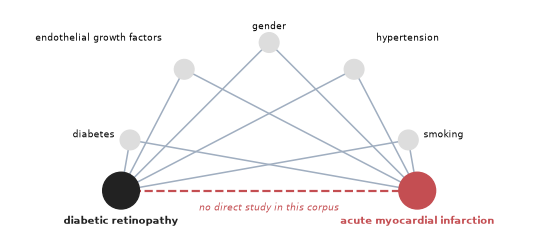

In [6]:
import os
import math
import matplotlib.pyplot as plt
import networkx as nx

INVESTIGATION_CANDIDATE = "acute myocardial infarction"  # set to None to just take the top-ranked candidate

if not confirmed:
    raise ValueError("No hypothesis candidates survived the direct-link check -- "
                     "try raising N_NEIGHBORS or PER_NEIGHBOR_CAP.")

top = next(
    (e for e in confirmed if e["label"].lower() == (INVESTIGATION_CANDIDATE or "").lower()),
    None,
)
if top is None:
    if INVESTIGATION_CANDIDATE:
        found = ", ".join(e["label"] for e in confirmed)
        print(f"'{INVESTIGATION_CANDIDATE}' isn't in the confirmed list, drawing the top-ranked "
              f"candidate instead. Available: {found}")
    top = confirmed[0]
shown_neighbors = sorted(top["neighbor_labels"])[:8]  # keep the picture readable

ANCHOR, CAND = "diabetic retinopathy", top["label"]

G = nx.Graph()
G.add_node(ANCHOR)
G.add_node(CAND)
for n_label in shown_neighbors:
    G.add_node(n_label)
    G.add_edge(ANCHOR, n_label)
    G.add_edge(n_label, CAND)

# ---- Deterministic layout: endpoints at the base, neighbors on an arc above ----
pos = {ANCHOR: (-1.0, 0.0), CAND: (1.0, 0.0)}
neighbor_labels = []   # (x, y, text, ha)
n_nb = len(shown_neighbors)
for i, n_label in enumerate(shown_neighbors):
    theta = math.radians(160 - 140 * i / max(n_nb - 1, 1))   # sweep 160° -> 20°
    x, y = 1.0 * math.cos(theta), 1.0 * math.sin(theta)
    pos[n_label] = (x, y)
    gap = 0.11 if i % 2 == 0 else 0.26                       # stagger alternate labels
    lx, ly = (1.0 + gap) * math.cos(theta), (1.0 + gap) * math.sin(theta)
    ha = "center" if abs(math.cos(theta)) < 0.25 else ("left" if math.cos(theta) > 0 else "right")
    neighbor_labels.append((lx, ly, n_label, ha))

# ---- Draw at final print size (5.5in = NeurIPS text-block width) ----
fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.set_ylim(-0.42, 1.35)
nx.draw_networkx_edges(G, pos, width=1.1, edge_color="#a0aec0", ax=ax)

# The hypothesis: the edge that isn't there.
ax.plot([pos[ANCHOR][0], pos[CAND][0]], [pos[ANCHOR][1], pos[CAND][1]],
        linestyle="--", linewidth=1.6, color="#C44E52", zorder=0)
ax.text(0, -0.08, "no direct study in this corpus", fontsize=6.5, style="italic",
        color="#C44E52", ha="center", va="top")

node_colors, node_sizes = [], []
for n in G.nodes:
    if n == ANCHOR:
        node_colors.append("#222222"); node_sizes.append(700)
    elif n == CAND:
        node_colors.append("#C44E52"); node_sizes.append(700)
    else:
        node_colors.append("#DDDDDD"); node_sizes.append(200)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, ax=ax)

for lx, ly, text, ha in neighbor_labels:
    ax.text(lx, ly, text, fontsize=6.5, ha=ha, va="center", color="black")

# Endpoint labels below their nodes, bold, so long candidate names stay readable.
ax.text(pos[ANCHOR][0], -0.17, ANCHOR, fontsize=7.5, fontweight="bold",
        ha="center", va="top", color="#222222")
ax.text(pos[CAND][0], -0.17, CAND, fontsize=7.5, fontweight="bold",
        ha="center", va="top", color="#C44E52")

# No in-figure title: the LaTeX caption carries the neighbor count and framing.
ax.set_xlim(-1.75, 1.75)
ax.set_ylim(-0.32, 1.22)
ax.set_aspect("equal")
ax.axis("off")
fig.tight_layout()

print(f"{ANCHOR} <-> {CAND}: {len(top['neighbor_labels'])} shared neighbors "
      f"({n_nb} shown), no direct study in this corpus")

out_path = os.path.abspath("missing.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print(f"Saved: {out_path}  ({os.path.getsize(out_path):,} bytes)")

plt.show()

## Final note

One important caveat regarding gaps: "no direct study in this corpus" is not the same as "never studied anywhere." The first step for any candidate here is a targeted literature search, and if that comes back empty, you're holding a confirmed open research question, found in a few minutes of graph traversal.

You've now completed the trilogy of demos showcasing what's possible with the System Public Graph. We look forward to seeing what you model, synthesize, and hypothesize in future.